In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import copy
import hydra
from hydra import initialize, compose
from omegaconf import DictConfig

from omniisaacgymenvs.utils.hydra_cfg.hydra_utils import *
from omniisaacgymenvs.utils.hydra_cfg.reformat import omegaconf_to_dict, print_dict
from omniisaacgymenvs.utils.task_util import initialize_task
from omniisaacgymenvs.envs.vec_env_rlgames import VecEnvRLGames

In [2]:
from os.path import join, dirname
import os
import sys
import time

import torch
from torch import nn, einsum
import torch.nn.functional as F
from torch.distributions import Normal, MultivariateNormal

from einops import rearrange, repeat

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.processing.vectorize import input_to_tensor, fourier_encode

%load_ext autoreload
%autoreload 2
%env ISAAC_JUPYTER_KERNEL=1

env: ISAAC_JUPYTER_KERNEL=1


/isaac-sim/kit/python/lib/python3.7/site-packages/IPython/extensions/autoreload.py:121: DeprecationWarning: the imp module is deprecated in favour of importlib; see the module's documentation for alternative uses
  from imp import reload


In [3]:
import torch

# Set the manual seed
seed = 42
torch.manual_seed(seed)

# Generate 10 random numbers
random_numbers_1 = [torch.rand(1).item() for _ in range(10)]
print("Random Numbers 1:", random_numbers_1)

# Save the state of the generator
state = torch.get_rng_state()

# Set the generator to the same manual seed
torch.manual_seed(seed)

# Generate 5 random numbers again
random_numbers_2 = [torch.rand(1).item() for _ in range(5)]
print("Random Numbers 2:", random_numbers_2)

# Load the generator state (G0)
torch.set_rng_state(state)

# Generate 5 random numbers using the loaded state
# random_numbers_loaded_state = [torch.rand(1).item() for _ in range(5)]
# print("Random Numbers Loaded State:", random_numbers_loaded_state)


Random Numbers 1: [0.8822692632675171, 0.9150039553642273, 0.38286375999450684, 0.9593056440353394, 0.3904482126235962, 0.600895345211029, 0.2565724849700928, 0.7936413288116455, 0.9407714605331421, 0.13318592309951782]
Random Numbers 2: [0.8822692632675171, 0.9150039553642273, 0.38286375999450684, 0.9593056440353394, 0.3904482126235962]


In [4]:
torch.rand(1)

tensor([0.9346])

In [5]:
torch.equal(state, torch.get_rng_state())

False

In [6]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device_cpu = torch.device("cpu")
random.seed(0)
np.random.seed(0)
torch.use_deterministic_algorithms(False)
%env CUBLAS_WORKSPACE_CONFIG=:4096:8

env: CUBLAS_WORKSPACE_CONFIG=:4096:8


In [7]:
nb_frames = 32
frames_future = 8
len_video_frame = 1824  # 456*256/(8*8)
len_audio_frame = 120   # 1920/16
query_dim = 832
video_latent_dim = 256
audio_latent_dim = 560
batch_size = 1

len_vid = nb_frames*len_video_frame
len_audio = nb_frames*len_audio_frame
len_audio_raw = len_audio*cf.sample_per_frame
video_future = frames_future*len_video_frame
audio_future = frames_future*len_audio_frame

special_compression = [i for i in range(video_future)] + [i for i in range(len_vid, len_vid+audio_future)]
for k in range(len(cf.body_parts)):
    special_compression += [ len_vid + len_audio + k*nb_frames + i for i in range(frames_future) ]

In [8]:
def create_model( device=device):

    # Projection to return modalities, enhancement

    modality_parameters = {}
    modality_parameters['audio'] = audio_latent_dim
    modality_parameters['video'] = video_latent_dim
    for part, params in cf.body_parts.items():
        modality_parameters[part] = query_dim - 2*128 - params
    for part, params in cf.body_outputs.items():
        modality_parameters[part] = query_dim - 2*128 - params

    projection_parameters = dict(cf.body_outputs)
    projection_parameters.update({'audio': 16})

    # Instantiate model
        
    model = PerceiverIO(
            2,
            query_dim,
            special_compression = special_compression,
            device=device,
            projection_parameters = projection_parameters,
            modality_parameters = modality_parameters,
            max_batch_size = batch_size
        )
    model = model.to(device)

    # Queries

    queries = []
    audio_query = repeat( torch.cat([model.modality['audio'], torch.zeros(16, device=device)]), '... -> n ...', n=audio_future)
    audio_pos = fourier_encode(torch.linspace(-1, 1, audio_future), audio_future/2, num_bands=128).to(device)
    queries.append(torch.cat([audio_query, audio_pos], dim=-1).to(device))
    for part, params in cf.body_outputs.items():
        part_query = repeat( torch.cat([model.modality[part], torch.zeros(params, device=device)]), '... -> n ...', n=frames_future)
        part_pos = fourier_encode(torch.linspace(-1, 1, frames_future), frames_future/2, num_bands=128).to(device)
        queries.append(torch.cat([part_query, part_pos], dim=-1).to(device))
    model.queries=torch.cat(queries)


    return model

In [9]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=64):
        super(ActorCritic, self).__init__()
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.hidden_dim = hidden_dim
        self.actor = nn.Sequential( nn.Linear(state_dim, hidden_dim),
                                    nn.ReLU(),
                                    nn.Linear(hidden_dim, hidden_dim),
                                    nn.ReLU(),
                                    nn.Linear(hidden_dim, 2*action_dim)
                                    ).to(device)

        self.critic = nn.Sequential(nn.Linear(state_dim, hidden_dim),
                                    nn.ReLU(),
                                    nn.Linear(hidden_dim, hidden_dim),
                                    nn.ReLU(),
                                    nn.Linear(hidden_dim, 1)
                                    ).to(device)
        
    def act(self, state):

        # Actor

        actions_tmp = torch.tanh(self.actor(state))
        actions_mean,  = actions_tmp[:, 0:self.action_dim], 
        actions_var = ((1+actions_tmp[:, self.action_dim:2*self.action_dim+1])/4+1e-5)**2
        dist = MultivariateNormal(actions_mean, torch.diag_embed(actions_var))
        actions = dist.sample()
        logprobs = dist.log_prob(actions)

        # Critic

        values = self.critic(state)
        values = rearrange(values,  'b 1 -> b')

        return actions.detach(), logprobs.detach(), values.detach(), dist

    def evaluate(self, state, actions):

        # Actor

        actions_tmp = torch.tanh(self.actor(state))
        actions_mean,  = actions_tmp[:, 0:self.action_dim], 
        actions_var = ((1+actions_tmp[:, self.action_dim:2*self.action_dim+1])/4+1e-5)**2
        dist = MultivariateNormal(actions_mean, torch.diag_embed(actions_var))
        logprobs = dist.log_prob(actions)
        entropies = dist.entropy() 

        # Critic

        values = self.critic(state)
        values = rearrange(values,  'b 1 -> b')

        return logprobs, values, entropies, dist

model = ActorCritic(4 ,1)
model_student = ActorCritic(4 ,1)
# model.act(torch.randn(8, 4, device=device))

/isaac-sim/kit/python/lib/python3.7/site-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'config': Defaults list is missing `_self_`. See https://hydra.cc/docs/upgrades/1.0_to_1.1/default_composition_order for more information
  warnings.warn(msg, UserWarning)
/isaac-sim/kit/python/lib/python3.7/site-packages/hydra/_internal/defaults_list.py:412: UserWarning: In config: Invalid overriding of hydra/job_logging:
Default list overrides requires 'override' keyword.
See https://hydra.cc/docs/next/upgrades/1.0_to_1.1/defaults_list_override for more information.

  deprecation_warning(msg)


Starting kit application with the following args:  ['/isaac-sim/exts/omni.isaac.kit/omni/isaac/kit/simulation_app.py', '/isaac-sim/apps/omni.isaac.sim.python.gym.headless.kit', '--/app/tokens/exe-path=/isaac-sim/kit', '--/persistent/app/viewport/displayOptions=3094', '--/rtx/materialDb/syncLoads=True', '--/rtx/hydra/materialSyncLoads=True--/omni.kit.plugin/syncUsdLoads=True', '--/app/renderer/resolution/width=1280', '--/app/renderer/resolution/height=720', '--/app/window/width=1440', '--/app/window/height=900', '--/renderer/multiGpu/enabled=True', '--/app/fastShutdown=False', '--ext-folder', '/isaac-sim/exts', '--ext-folder', '/isaac-sim/apps', '--/physics/cudaDevice=0', '--portable', '--no-window', '--allow-root']
Passing the following args to the base kit application:  ['-f', '/root/.local/share/jupyter/runtime/kernel-d652d000-06b8-429c-be3c-c2ed4907267b.json']


[Warning] [omni.isaac.kit.simulation_app] Modules: ['omni.isaac.kit.app_framework'] were loaded before SimulationApp was started and might not be loaded correctly.
[Warning] [omni.isaac.kit.simulation_app] Please check to make sure no extra omniverse or pxr modules are imported before the call to SimulationApp(...)
[Warning] [omni.isaac.kit.simulation_app] fast shutdown not supported with jupyter notebooks
[Warning] [omni.kit.app.plugin] No crash reporter present, dumps uploading isn't available.
[Info] [carb] Logging to file: /isaac-sim/kit/logs/Kit/Isaac-Sim/2022.2/kit_20230817_153218.log
2023-08-17 15:32:18 s] [Warning] [omni.ext.plugin] [ext: omni.sensors.nv.lidar] Extensions config 'extension.toml' doesn't exist '/isaac-sim/exts/omni.sensors.nv.lidar' or '/isaac-sim/exts/omni.sensors.nv.lidar/config'
2023-08-17 15:32:18 s] [Warning] [omni.ext.plugin] [ext: omni.sensors.nv.radar] Extensions config 'extension.toml' doesn't exist '/isaac-sim/exts/omni.sensors.nv.radar' or '/isaac-sim

/isaac-sim/kit/exts/omni.graph/omni/graph/core/_impl/autonode/type_definitions.py:12: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  Float = NewType("Float", np.float)


],[carb::windowing::IWindowing v1.3]) (impl: carb.windowing-glfw.plugin)
2023-08-17 15:32:20 [1,911ms] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2023-08-17 15:32:20 [1,911ms] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContext v1.0],[carb::windowing::IWindowing v1.3]) (impl: carb.windowing-glfw.plugin)
[1.927s] [ext: omni.kit.renderer.capture-0.0.0] startup
[1.931s] [ext: omni.kit.renderer.imgui-0.0.0] startup
2023-08-17 15:32:20 [1,925ms] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2023-08-17 15:32:20 [1,925ms] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContext v1.0],[carb::windowing::IWindowing v1.3]) (impl: carb.windowing-glfw.plugin)
2023-08-17 15:32:20 [1,926ms] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2023-08-17 15:32:20 [1,926ms] [Warning] [carb] Failed to startup plugin carb.windowing-glf

/isaac-sim/kit/kernel/py/omni/kit/app/_impl/__init__.py:104: DeprecationWarning: Using or importing the ABCs from 'collections' instead of from 'collections.abc' is deprecated since Python 3.3,and in 3.9 it will stop working
  if not isinstance(setting_py, str) and isinstance(setting_py, collections.Sequence):


Warp 0.6.3 initialized:
   CUDA Toolkit: 11.5, Driver: 12.2
   Devices:
     "cpu"    | x86_64
     "cuda:0" | NVIDIA RTX A2000 12GB (sm_86)
   Kernel cache: /root/.cache/warp/0.6.3
Setting seed: 42
Sim params does not have attribute:  physx
Sim params does not have attribute:  Cartpole
Pipeline:  GPU
Pipeline Device:  cuda:0
Sim Device:  GPU
rial.library-1.3.21] startup
[3.104s] [ext: omni.kit.browser.core-2.2.2] startup
[3.111s] [ext: omni.kit.window.file_exporter-1.0.10] startup
[3.113s] [ext: omni.physics.tensors-0.1.0] startup
[3.125s] [ext: omni.kit.browser.folder.core-1.7.3] startup
[3.131s] [ext: omni.kit.window.file-1.3.32] startup
[3.135s] [ext: omni.physx.tensors-0.1.0] startup
[3.144s] [ext: omni.isaac.version-1.0.0] startup
[3.145s] [ext: omni.kit.browser.sample-1.2.5] startup
[3.149s] [ext: omni.isaac.cloner-0.4.1] startup
[3.150s] [ext: omni.isaac.core-1.46.3] startup
[3.428s] [ext: omni.warp-0.6.3] startup
[4.051s] [ext: omni.kit.window.title-1.1.2] startup
2023-08-17 1

/isaac-sim/kit/python/lib/python3.7/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


mni.kit.viewport.bundle-104.0.2] startup
[4.618s] [ext: omni.volume-0.1.0] startup
[4.632s] [ext: omni.hydra.rtx-0.1.0] startup
[4.644s] [ext: omni.activity.core-1.0.1] startup
[4.649s] [ext: omni.kit.window.property-1.8.2] startup
[4.658s] [ext: omni.kit.widget.prompt-1.0.5] startup
[4.662s] [ext: omni.kit.widget.graph-1.5.6-104_2] startup
[4.684s] [ext: omni.kit.widget.text_editor-1.0.2] startup
[4.686s] [ext: omni.debugdraw-0.1.1] startup
[4.696s] [ext: omni.kit.window.extensions-1.1.1] startup
[4.704s] [ext: omni.inspect-1.0.1] startup
[4.708s] [ext: omni.kit.widget.stage-2.7.24] startup
[4.715s] [ext: omni.kit.property.usd-3.18.17] startup
[4.729s] [ext: omni.graph.ui-1.24.2] startup
[4.788s] [ext: omni.graph.scriptnode-0.10.0] startup
[4.792s] [ext: omni.command.usd-1.0.2] startup
[4.795s] [ext: omni.graph.action-1.31.1] startup
[4.809s] [ext: omni.syntheticdata-0.2.4] startup
2023-08-17 15:32:23 [4,821ms] [Warning] [omni.kit.viewport.menubar.core.menu_item.viewport_menu_item] Vi

TypeError: manual_seed() got an unexpected keyword argument 'device'

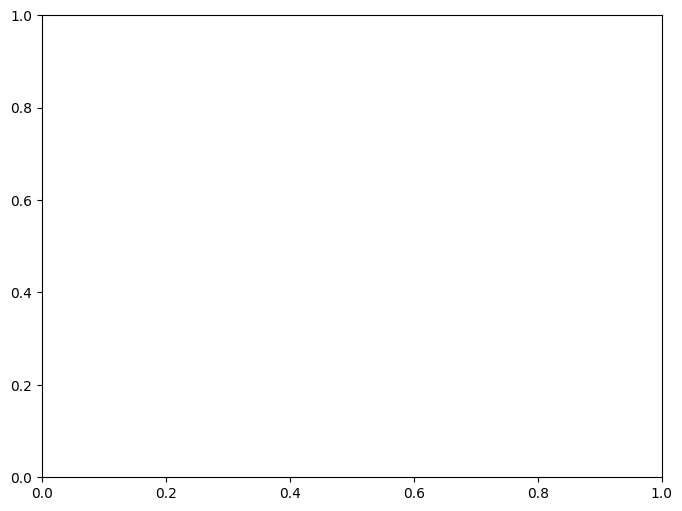

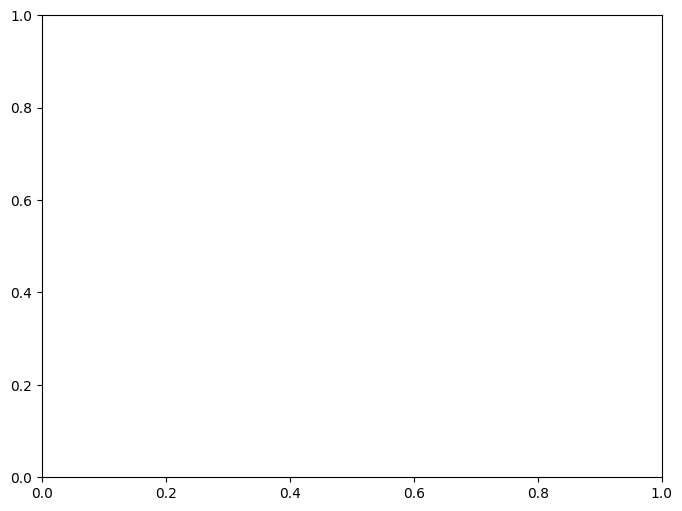

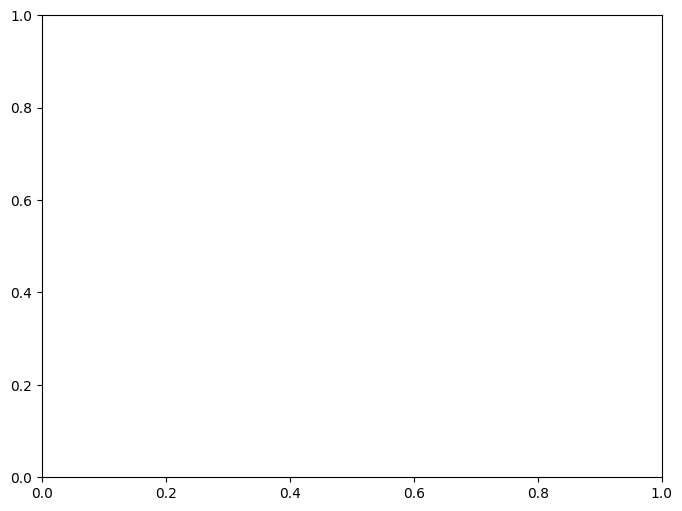

In [10]:
#@hydra.main(config_name="config", config_path="../cfg")
#@hydra.main(config_name="config", config_path="../../OmniIsaacGymEnvs/omniisaacgymenvs/cfg")
def parse_hydra_configs(cfg: DictConfig):

    def buffer_padding(buffer, dim, default_value=None, frames=32):
        
        # zero padding then transform: t b (d) -> b t (d)

        device = buffer.device
        pad0 = np.max([0, frames-len(buffer)])
        if default_value is None:
            padding = torch.zeros([pad0, numEnvs]+dim, device=device)
        else:
            padding = repeat(default_value, ' ... -> t0 b ...', t0=pad0, b=numEnvs).to(device)
        res = torch.swapaxes( 
                torch.cat([ padding, buffer ])
                , 0, 1)
        return res

    def update_buffer(buff, key, element, frames=32):
        buff[key].append(element)
        if(len(buff[key])>frames):
            buff[key].pop(0)

    def calculate_returns(rewards_mem, death_index, gamma=0.99):
        sim_duration, numEnvs = rewards_mem.size()
        returns_estimates = torch.zeros_like(rewards_mem)
        for env_idx in range(numEnvs):
            sum = 0.0
            for t in reversed(range(sim_duration)):
                # If the agent is reset, set to 0
                if t in death_index[env_idx]:
                    sum = 0

                # Reverse calcualtion of returns
                sum = gamma*sum + rewards_mem[t, env_idx]
                returns_estimates[t, env_idx] = sum
            
        return returns_estimates


    def calculate_gae(rewards_mem, values_mem, death_index, gamma=0.99, gae_lambda=0.95):
        sim_duration, numEnvs = rewards_mem.size()
        gae_estimates = torch.zeros_like(rewards_mem)

        for env_idx in range(numEnvs):
            gae = 0.0 
            for t in reversed(range(sim_duration)):
                # If the agent is reset, set GAE to 0
                if t in death_index[env_idx]:
                    gae = 0.0
                    
                # Calculate the TD error and gae
                if t == sim_duration-1:
                    delta_t = values_mem[t, env_idx]  
                else:
                    delta_t= rewards_mem[t, env_idx] + gamma * values_mem[t+1, env_idx] - values_mem[t, env_idx]
                gae_estimates[t, env_idx] = delta_t + gamma * gae_lambda * gae
            
        return gae_estimates
    
    def two_levels_plot(data, ax, fig, horizon, path):
        ax.clear()
        recent_data=data[-horizon:]
        ax.plot(recent_data, alpha=0.5)
        ax.plot((np.convolve(data, np.ones(horizon), 'valid') / horizon)[::max(1,int(len(data)/horizon))])
        # ax.set_ylim(bottom=np.min(recent_data), top=np.max(recent_data))
        fig.savefig(path)

    def update_lr(current_lr, kl_div, kl_threshold=0.08, min_lr=1e-6, max_lr=1e-2):
        lr = current_lr
        if kl_div > (2.0 * kl_threshold):
            lr = max(current_lr / 1.5, min_lr)
        if kl_div < (0.5 * kl_threshold):
            lr = min(current_lr * 1.5, max_lr)
        return lr    

    def create_mask(birth_time, sim_step, frames=32):
        numEnvs = birth_time.size()
        past_horizon=torch.max(-nb_frames*torch.ones(numEnvs), 
                                torch.min(sim_step-birth_time, -1*torch.ones(numEnvs)))
        mask = repeat(torch.arrange(nb_frames), '... -> b ...', b=numEnvs) < repeat(past_horizon, '... -> ... t', t=nb_frames)
        return mask


    cfg_dict = omegaconf_to_dict(cfg)

    headless = cfg.headless
    render = not headless
    render = True

    env = VecEnvRLGames(headless=headless, sim_device=cfg.device_id)
    # sets seed. if seed is -1 will pick a random one
    from omni.isaac.core.utils.torch.maths import set_seed
    # from omni.isaac.core.utils.stage import open_stage, save_stage
    cfg.seed = set_seed(cfg.seed, torch_deterministic=cfg.torch_deterministic)
    cfg_dict['seed'] = cfg.seed
    task = initialize_task(cfg_dict, env)

    history = {'video':[], 'audio':[], 'obs':[], 'reward':[], 'action':[], 'values': [], 'logprobs':[], 'generator':[]}
    buffer = {'video':[], 'audio':[], 'obs':[], 'reward':[], 'action':[]}
    generator_mem = torch.zeros(sim_duration, 5056, dtype=torch.uint8,  device=device)
    replay_training=True  # Will switch to false immediately
    memories = {i:None for i in range(numEnvs)}
    death_index = {i:[] for i in range(numEnvs)}
    all_losses, all_losses_critic, all_returns = [], [], []
    fig_loss, ax_loss = plt.subplots(figsize=(8, 6))
    fig_loss_critic, ax_loss_critic = plt.subplots(figsize=(8, 6))
    fig_rewards, ax_rewards = plt.subplots(figsize=(8, 6))
    path_plots = '/isaac-sim/memoryPerceiver/memory_perceiver/main/'
    path_stage = '/isaac-sim/memoryPerceiver/memory_perceiver/main/stage.usd'
    optimizer = torch.optim.Adam(model_student.parameters(), lr=learning_rate)
    sim_count, sim_step = 0, 0
    first_run=True
    while env._simulation_app.is_running():
        if env._world.is_playing():
            # if env._world.current_time_step_index == 0 or \
            # env._world.current_time_step_index % sim_duration == 0:
            if env.sim_frame_count % sim_duration == 0:

                ### Plots

                if sim_count % 6 == 1 and len(all_losses)>0:
                    two_levels_plot(all_losses, ax_loss, fig_loss, horizon=160, path=path_plots+'loss.png')
                    two_levels_plot(all_losses_critic, ax_loss_critic, fig_loss_critic, horizon=160, path=path_plots+'loss_critic.png')
                    ax_rewards.plot(all_returns)
                    fig_rewards.savefig(path_plots+'returns.png')

                ### Initialization

                env._world.reset(soft=False)
                replay_training = not replay_training
                print('$$$$$$$$$$$ CUMUL REWARD $$$$$$$$$$$')
                if len(history['reward'])>0:
                    print(torch.stack(history['reward']).sum())
                if replay_training:
                    print('REPLAY')
                    # open_stage(path_stage)
                    first_run=False
                    # model.reset_memories()
                    # model_student.reset_memories()
                    model_student.train() 
                    optimizer.zero_grad()
                    values_mem = torch.stack(history['values'])
                    rewards_mem = torch.stack(history['reward'])
                    actions_mem = torch.stack(history['action'])
                    logprobs_mem = torch.stack(history['logprobs'])
                    # generator_mem = torch.stack(history['generator'])
                    returns_mem = calculate_returns(rewards_mem, death_index, gamma=c_gamma)
                    advantages_mem = calculate_gae(rewards_mem, values_mem, death_index, 
                                                   gamma=c_gamma, gae_lambda=c_lambda)
                    preview=150
                    # print('values: ', values_mem[:preview, 0])
                    # print('rewards: ', rewards_mem[:preview, 0])
                    # print('returns: ', returns_mem[:preview, 0])
                    # print('advantages: ', advantages_mem[:preview, 0])
                    # print('actions: ', actions_mem[:preview, 0, 0])
                    all_returns.append(returns_mem[1, :].mean().item())
                else:
                    print('PLAY')
                    # save_stage(path_stage)
                    if first_run and os.path.exists(path_model):
                        model.load_state_dict(torch.load(path_model))
                        model_student.load_state_dict(torch.load(path_model))
                    else:
                        if sim_count % student_update_step*2 == 0:
                            model.load_state_dict(model_student.state_dict())
                    # model.reset_memories()
                    torch.save(model_student.state_dict(), path_model)
                    model.eval()
                    death_index = {i:[] for i in range(numEnvs)}
                    generator_mem = torch.zeros(sim_duration, 5056, dtype=torch.uint8,  device=device)
                    
                torch.manual_seed(sim_count//2)
                memories = {i:None for i in range(numEnvs)}
                birth_time = torch.zeros(numEnvs)
                for key in buffer.keys():
                    buffer[key]=[]
                for key in history.keys():
                    history[key]=[]
                backward_count, kl_div = 0, 0
                sim_count+=1
                sim_step = 0

            # if sim_step == 0:
            #     env._task.post_reset()
            #     env._task.reset_buf[:] = 1

            ### Observations: 'cartpole_view' 'obs_buf' (numEnvs, 4)

            all_obs = env._task.get_observations()['cartpole_view']
            obs = all_obs['obs_buf'].clone()
            update_buffer(buffer, 'obs', obs)
            history['obs'].append(obs)

            ### Video: 'cartpole_view' 'obs_buf' (numEnvs, 3, 256, 456)

            # vid = all_obs['video_buf'].clone()
            # update_buffer(buffer, 'video', vid)

            ### Reward (numEnvs, 1)

            env._task.calculate_metrics()
            reward=env._task.rew_buf.clone()
            update_buffer(buffer, 'reward', reward)
            history['reward'].append(reward)
            if replay_training:
                print('r0', rewards_mem[sim_step][0], 'r1', reward[0])

            ### returns/ Return


            for agent_i in range(numEnvs):

                # Reset goal and memory when dying

                if env._task.reset_buf[agent_i].item() == 1:
                    memories[agent_i] = None
                    birth_time[agent_i] = sim_step

                    # Update death dictionnary during inference

                    if not replay_training:
                        death_index[agent_i].append(sim_step)


            ### Process input

            inputs={}
            inputs['video'] = torch.zeros(numEnvs, 3, nb_frames, 256, 456, device=device)
            # inputs['video'] = rearrange(buffer_padding(buffer['video'], [3, 256, 456]), 'b t c h w -> b c t h w')
            inputs['audio'] = torch.zeros(numEnvs, nb_frames*1920, device=device)

            ### Agent
            
            inference_done = False
            if len(buffer['action'])==0 :
                inference_done = True
                inputs['observations'] = buffer_padding(torch.stack(buffer['obs']), [cf.body_parts['observations']])
                # mask = create_mask(birth_time, sim_step)
                # inputs['observations'][mask] *= 0
                dt=1
                state = inputs['observations'][:,-1]


                ## Inference and memory update

                if not replay_training:
                    actions, logprobs, values, old_dist = model.act(state)                    
                    generator_mem[sim_step] = torch.get_rng_state( device=device).clone()
                if replay_training:
                    actions0 = rearrange( buffer_padding(actions_mem[sim_step: sim_step+dt], [1], frames=1), 'b 1 d -> b d')
                    logprobs0 = rearrange( buffer_padding(logprobs_mem[sim_step: sim_step+dt], [], frames=1),  'b 1 -> b')
                    values0 = rearrange( buffer_padding(values_mem[sim_step: sim_step+dt], [], frames=1),  'b 1 -> b')
                    # print('gen', torch.equal(torch.get_rng_state(), generator_mem[sim_step]))
                    # print('act0', actions[0], 'act1', actions0[0])
                    torch.set_rng_state(generator_mem[sim_step],  device=device)
                                    

                ## Backward pass

                if replay_training and sim_step>0:

                    returns = rearrange( buffer_padding(returns_mem[sim_step:sim_step+dt], [], frames=1) , 'b 1 -> b')
                    advantages = rearrange( buffer_padding(advantages_mem[sim_step:sim_step+dt], [], frames=1), 'b 1 -> b')
                    new_logprobs, new_values, entropies, new_dist = model_student.evaluate(state, actions)

                    # Loss
                    ratios = torch.exp(new_logprobs - logprobs)
                    surr1 = ratios * advantages
                    surr2 = torch.clamp(ratios, 1-eps_clip, 1+eps_clip) * advantages
                    loss_actor = -(torch.min(surr1, surr2)).mean()
                    loss_entropy = -c_entropy * entropies.mean()
                    loss_critic = c_critic * F.mse_loss(new_values, returns)
                    loss =  (loss_actor + loss_critic + loss_entropy) /accumulation_steps
                    loss.backward()
                    backward_count += 1
                    kl_div += torch.distributions.kl_divergence(new_dist, old_dist).mean()/accumulation_steps


                    # Step optimizer

                    if backward_count % accumulation_steps == 0 and backward_count != 0:
                        torch.nn.utils.clip_grad_norm_(model_student.parameters(), c_grad_norm)
                        optimizer.step()
                        optimizer.zero_grad()

                        # Adaptive schedule
                        for param_group in optimizer.param_groups:
                            param_group['lr'] = update_lr(param_group['lr'], kl_div)
                            # print('lr', param_group['lr'], 'kl', kl_div.item())

                        # Reinit
                        backward_count = 0
                        kl_div = 0


                    all_losses.append(loss_actor.item())
                    all_losses_critic.append(loss_critic.item())

                # Update buffers

                actions_inference = list(torch.unbind( repeat(actions, 'b d -> t b d', t=dt) ))
                buffer['action'] += actions_inference
                history['action'] += actions_inference
                history['values'] += list(torch.unbind( repeat(values, 'b -> t b', t=dt) ))
                history['logprobs'] += list(torch.unbind( repeat(logprobs, 'b -> t b', t=dt) ))


            ## Current action (numEnvs, 1)

            if(len(buffer['action'])>0):
                action = buffer['action'].pop(0)
                action = torch.clamp(action, min=-1, max=1)
            else:
                action = torch.dzeros(numEnvs, 1)

            # if( inference_done ):
            #     print('$$$$$$  INFERENCE  $$$$$$')
            #     print('obs ', inputs['observations'][agent_i,-1])
            #     if replay_training:
            #         print('advantages: ', advantages)

            # if env.sim_frame_count % sim_duration == 1:
            #     print("$$$$$$$$$$$$ 00000 $$$$$$$$$$$")
            #     if replay_training:
            #         print('returns: ', returns_tmp)

            # Step environment

            # if replay_training:
            #     print('gen pre', torch.equal(torch.get_rng_state(), generator_mem[sim_step]))

            env._task.pre_physics_step(action.to(task.rl_device))
            env._world.step(render=render)
            env.sim_frame_count += 1
            env._task.post_physics_step()

            # if replay_training:
            #     print('gen post', torch.equal(torch.get_rng_state(), generator_mem[sim_step]))

            sim_step+=1

        else:
            env._world.step(render=render)

    env._simulation_app.close()


if __name__ == '__main__':
    sim_duration = 257
    numEnvs = 8
    learning_rate = 0.0001
    accumulation_steps = 2
    c_entropy = 0
    c_critic=4
    student_update_step = 1
    eps=1e-9
    c_gamma=0.99
    c_lambda=0.95
    c_grad_norm=1.0
    eps_clip=0.2
    path_model = 'weights/cartpole.pt'
    critic_path = 'weights/critic.pt'
    with initialize(config_path="memoryPerceiver/OmniIsaacGymEnvs/omniisaacgymenvs/cfg"):
        cfg = compose(config_name="config", overrides=["task=Cartpole", "headless=True","+numEnvs="+str(numEnvs)])
    parse_hydra_configs(cfg)

: 